# **Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import math

import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report,roc_auc_score,roc_curve
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# **LOADING DATA**

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ict/House_Pricing.csv")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

df.head()

,ID,Date House was Sold,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Waterfront View,No of Times Visited,Condition of the House,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft)
0,7129300520,14 October 2017,221900.0,3,1.00,1180.0,5650.0,1.0,No,NaN,Fair,7,1180.0,0,63,0,98178.0,47.5112,-122.257,1340.0,5650
1,6414100192,14 December 2017,538000.0,3,2.25,2570.0,7242.0,2.0,No,NaN,Fair,7,2170.0,400,67,1991,98125.0,47.7210,-122.319,1690.0,7639
2,5631500400,15 February 2016,180000.0,2,1.00,770.0,10000.0,1.0,No,NaN,Fair,6,770.0,0,85,0,98028.0,47.7379,-122.233,2720.0,8062
3,2487200875,14 December 2017,604000.0,4,3.00,1960.0,5000.0,1.0,No,NaN,Excellent,7,1050.0,910,53,0,98136.0,47.5208,-122.393,1360.0,5000
4,1954400510,15 February 2016,510000.0,3,2.00,1680.0,8080.0,1.0,No,NaN,Fair,8,1680.0,0,31,0,98074.0,47.6168,-122.045,1800.0,7503


In [ ]:
# Convert to datetime and extract year
df['Year Sold'] = pd.to_datetime(df['Date House was Sold']).dt.year

# Drop the original date column
df = df.drop(columns=['Date House was Sold'])

df.drop(columns=['No of Times Visited'], inplace=True)
df.drop(columns=['ID'], inplace=True)
# Drop rows where target variable is missing
df = df.dropna(subset=['Sale Price'])

In [ ]:
# Displaying last 5 rows

df.tail()

,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Waterfront View,Condition of the House,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft),Year Sold
21608,360000.0,3,2.50,1530.0,1131.0,3.0,No,Fair,8,1530.0,0,9,0,98103.0,47.6993,-122.346,1530.0,1509,2017
21609,400000.0,4,2.50,2310.0,5813.0,2.0,No,Fair,8,2310.0,0,4,0,98146.0,47.5107,-122.362,1830.0,7200,2016
21610,402101.0,2,0.75,1020.0,1350.0,2.0,No,Fair,7,1020.0,0,9,0,98144.0,47.5944,-122.299,1020.0,2007,2017
21611,400000.0,3,2.50,1600.0,2388.0,2.0,No,Fair,8,1600.0,0,14,0,98027.0,47.5345,-122.069,1410.0,1287,2016
21612,325000.0,2,0.75,1020.0,1076.0,2.0,No,Fair,7,1020.0,0,10,0,98144.0,47.5941,-122.299,1020.0,1357,2017


In [ ]:
# Shape of the data

df.shape

(21609, 19)

In [ ]:
# Datatypes
df.dtypes

,0
Sale Price,float64
No of Bedrooms,int64
No of Bathrooms,float64
Flat Area (in Sqft),float64
Lot Area (in Sqft),float64
No of Floors,float64
Waterfront View,object
Condition of the House,object
Overall Grade,int64
Area of the House from Basement (in Sqft),float64


In [ ]:
# Checking missing values

df.isna().sum()

,0
Sale Price,0
No of Bedrooms,0
No of Bathrooms,4
Flat Area (in Sqft),9
Lot Area (in Sqft),9
No of Floors,0
Waterfront View,0
Condition of the House,0
Overall Grade,0
Area of the House from Basement (in Sqft),3


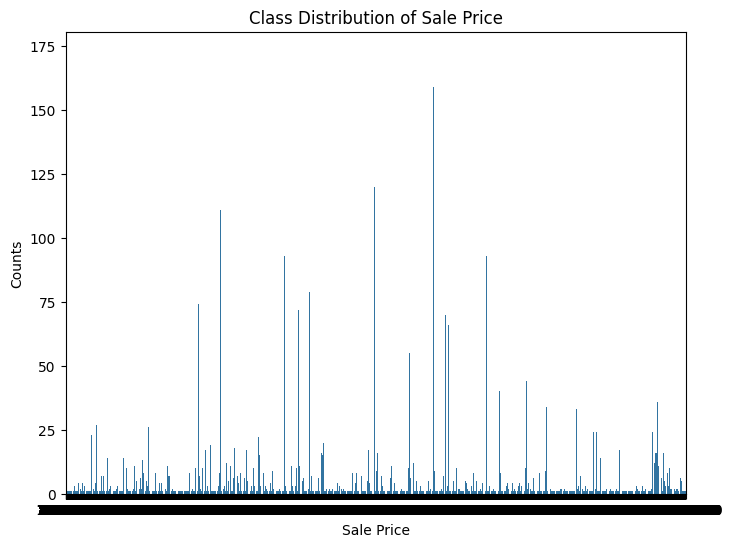

In [ ]:
# Checking the class imbalance

values_grade = df['Sale Price'].value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=values_grade.index, y=values_grade.values)

plt.xlabel("Sale Price")
plt.ylabel("Counts")
plt.title("Class Distribution of Sale Price")
plt.show()

# **Target**

In [ ]:
target_data = df["Sale Price"]


# Extracting target data's name
target = target_data.name

# **spliting**

In [ ]:
# df.drop(columns=['customer_id'], inplace=True, axis=1)

In [ ]:
df_clean = df.dropna(subset=['Sale Price'])

In [ ]:
X =df.drop(columns=["Sale Price"])
y = df["Sale Price"]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# **NUMERICAL** **VALUE** **ENCODING**

In [ ]:
from sklearn.impute import SimpleImputer

In [ ]:
# Numerical and categotical
sm =  SimpleImputer(strategy="median")

X_train_num = X_train.select_dtypes(exclude=["object"])
X_test_num = X_test.select_dtypes(exclude=["object"])

X_train_num_sm = sm.fit_transform(X_train_num)
X_test_num_sm = sm.transform(X_test_num)# we dont fit in test data

X_train_num_sm = pd.DataFrame(X_train_num_sm , columns=X_train_num.columns,index=X_train.index)
X_test_num_sm = pd.DataFrame(X_test_num_sm , columns=X_test_num.columns,index=X_test.index)

In [ ]:
X_test_num_sm.isna().sum()

,0
No of Bedrooms,0
No of Bathrooms,0
Flat Area (in Sqft),0
Lot Area (in Sqft),0
No of Floors,0
Overall Grade,0
Area of the House from Basement (in Sqft),0
Basement Area (in Sqft),0
Age of House (in Years),0
Renovated Year,0


# **CATAGORICAL** **VALUE**

In [ ]:
cat= SimpleImputer(strategy="most_frequent")
X_train_cat = X_train.select_dtypes(include=["object"])
X_test_cat = X_test.select_dtypes(include=["object"])

X_train_cat_mut = cat.fit_transform(X_train_cat)
X_test_cat_mut = cat.transform(X_test_cat)

X_train_cat_mut = pd.DataFrame(X_train_cat_mut,columns=X_train_cat.columns,index=X_train.index)
X_test_cat_mut = pd.DataFrame(X_test_cat_mut,columns=X_test_cat.columns,index=X_test.index)

In [ ]:
X_train_cat_mut.isna().sum()

,0
Waterfront View,0
Condition of the House,0


# **ENCODING**

In [ ]:
# Handling encodings


columns_cat = X_train_cat_mut.columns

for col in columns_cat:
  print(f"{col}: {X_train_cat_mut[col].unique()}")

Waterfront View: ['No' 'Yes']
Condition of the House: ['Good' 'Fair' 'Okay' 'Excellent' 'Bad']


**ONE** **HOT** **ENCODING**

In [ ]:
oh_encoding_cols = [
 'Condition of the House']

lb_encoding_cols = [col for col in X_train_cat_mut.columns if col not in oh_encoding_cols]
lb_encoding_cols



['Waterfront View']

**LABEL** **ENCODING**

In [ ]:
le = LabelEncoder()
oh = OneHotEncoder()

In [ ]:
labelenco = {}

# Copies to avoid setting-with-copy warnings
X_train_encoded = X_train_cat_mut.copy()
X_test_encoded = X_test_cat_mut.copy()

# Label Encoding
for col in lb_encoding_cols:
    le = LabelEncoder()
    X_train_encoded[col] = le.fit_transform(X_train_encoded[col])
    # Use transform (not fit_transform) on test set to prevent data leakage/mismatched labels
    X_test_encoded[col] = le.transform(X_test_encoded[col])
    labelenco[col] = le

# Keep only label-encoded columns temporarily
X_train_lb = X_train_encoded[lb_encoding_cols]
X_test_lb = X_test_encoded[lb_encoding_cols]

# One-Hot Encoding
oh = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

train_oh = pd.DataFrame(
    oh.fit_transform(X_train_cat_mut[oh_encoding_cols]),
    columns=oh.get_feature_names_out(oh_encoding_cols),
    index=X_train_cat_mut.index
)

test_oh = pd.DataFrame(
    oh.transform(X_test_cat_mut[oh_encoding_cols]),
    columns=oh.get_feature_names_out(oh_encoding_cols),
    index=X_test_cat_mut.index
)

# Combine label-encoded and one-hot-encoded categorical features
X_train_encoded = pd.concat([X_train_lb, train_oh], axis=1)
X_test_encoded = pd.concat([X_test_lb, test_oh], axis=1)

In [ ]:
# Final concatination of cat and num values

X_train_final = pd.concat([X_train_num_sm, train_oh], axis=1)
X_test_final = pd.concat([X_test_num_sm, test_oh], axis=1)

In [ ]:
X_train_final.head()

,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft),Year Sold,Condition of the House_Bad,Condition of the House_Excellent,Condition of the House_Fair,Condition of the House_Good,Condition of the House_Okay
7095,3.0,2.50,2030.0,8398.0,2.0,9.0,2030.0,0.0,43.0,0.0,98008.0,47.6272,-122.095,2450.0,8104.0,2017.0,0.0,0.0,0.0,1.0,0.0
18538,3.0,1.00,1230.0,7020.0,1.0,7.0,1090.0,140.0,94.0,0.0,98116.0,47.5719,-122.390,1390.0,5850.0,2017.0,0.0,0.0,1.0,0.0,0.0
20023,3.0,2.25,1481.0,2820.0,2.0,7.0,1481.0,0.0,6.0,0.0,98002.0,47.3457,-122.217,1481.0,3028.0,2017.0,0.0,0.0,1.0,0.0,0.0
6254,5.0,3.25,3320.0,11340.0,2.0,8.0,2480.0,840.0,19.0,0.0,98042.0,47.3904,-122.154,2330.0,8339.0,2017.0,0.0,0.0,0.0,1.0,0.0
15383,4.0,2.50,2105.0,6093.0,2.0,8.0,2105.0,0.0,15.0,0.0,98042.0,47.3531,-122.147,1930.0,8022.0,2017.0,0.0,0.0,1.0,0.0,0.0


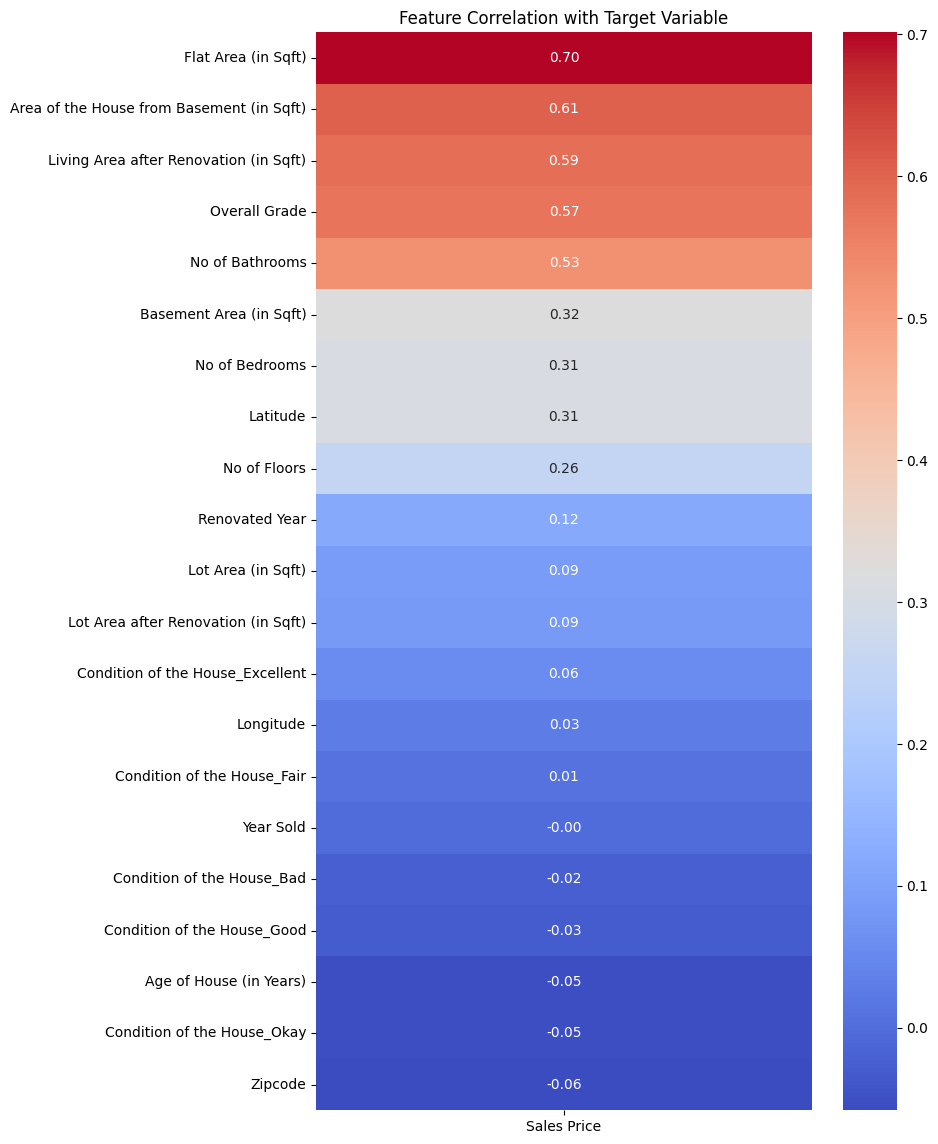

In [ ]:
corr_cat_result = X_train_final.corrwith(
    pd.Series(y_train, index=X_train_final.index)
)

corr_cat_result = corr_cat_result.sort_values(ascending=False)

# Convert Series to DataFrame
target_corr_df = corr_cat_result.to_frame(name="Sales Price")

plt.figure(figsize=(8, 14))

sns.heatmap(
    target_corr_df,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation with Target Variable")
plt.show()

# **OUTLIER TREATMENT**

In [ ]:
# List the few columns you WANT to keep
columns_to_keep = df.columns
# Find all columns that are NOT in your keep list
columns_to_drop = [col for col in df.columns if col not in columns_to_keep]

# Drop all remaining columns in-place
df.drop(columns=columns_to_drop, inplace=True)

In [ ]:
df.head()

,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Waterfront View,Condition of the House,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft),Year Sold
0,221900.0,3,1.00,1180.0,5650.0,1.0,No,Fair,7,1180.0,0,63,0,98178.0,47.5112,-122.257,1340.0,5650,2017
1,538000.0,3,2.25,2570.0,7242.0,2.0,No,Fair,7,2170.0,400,67,1991,98125.0,47.7210,-122.319,1690.0,7639,2017
2,180000.0,2,1.00,770.0,10000.0,1.0,No,Fair,6,770.0,0,85,0,98028.0,47.7379,-122.233,2720.0,8062,2016
3,604000.0,4,3.00,1960.0,5000.0,1.0,No,Excellent,7,1050.0,910,53,0,98136.0,47.5208,-122.393,1360.0,5000,2017
4,510000.0,3,2.00,1680.0,8080.0,1.0,No,Fair,8,1680.0,0,31,0,98074.0,47.6168,-122.045,1800.0,7503,2016


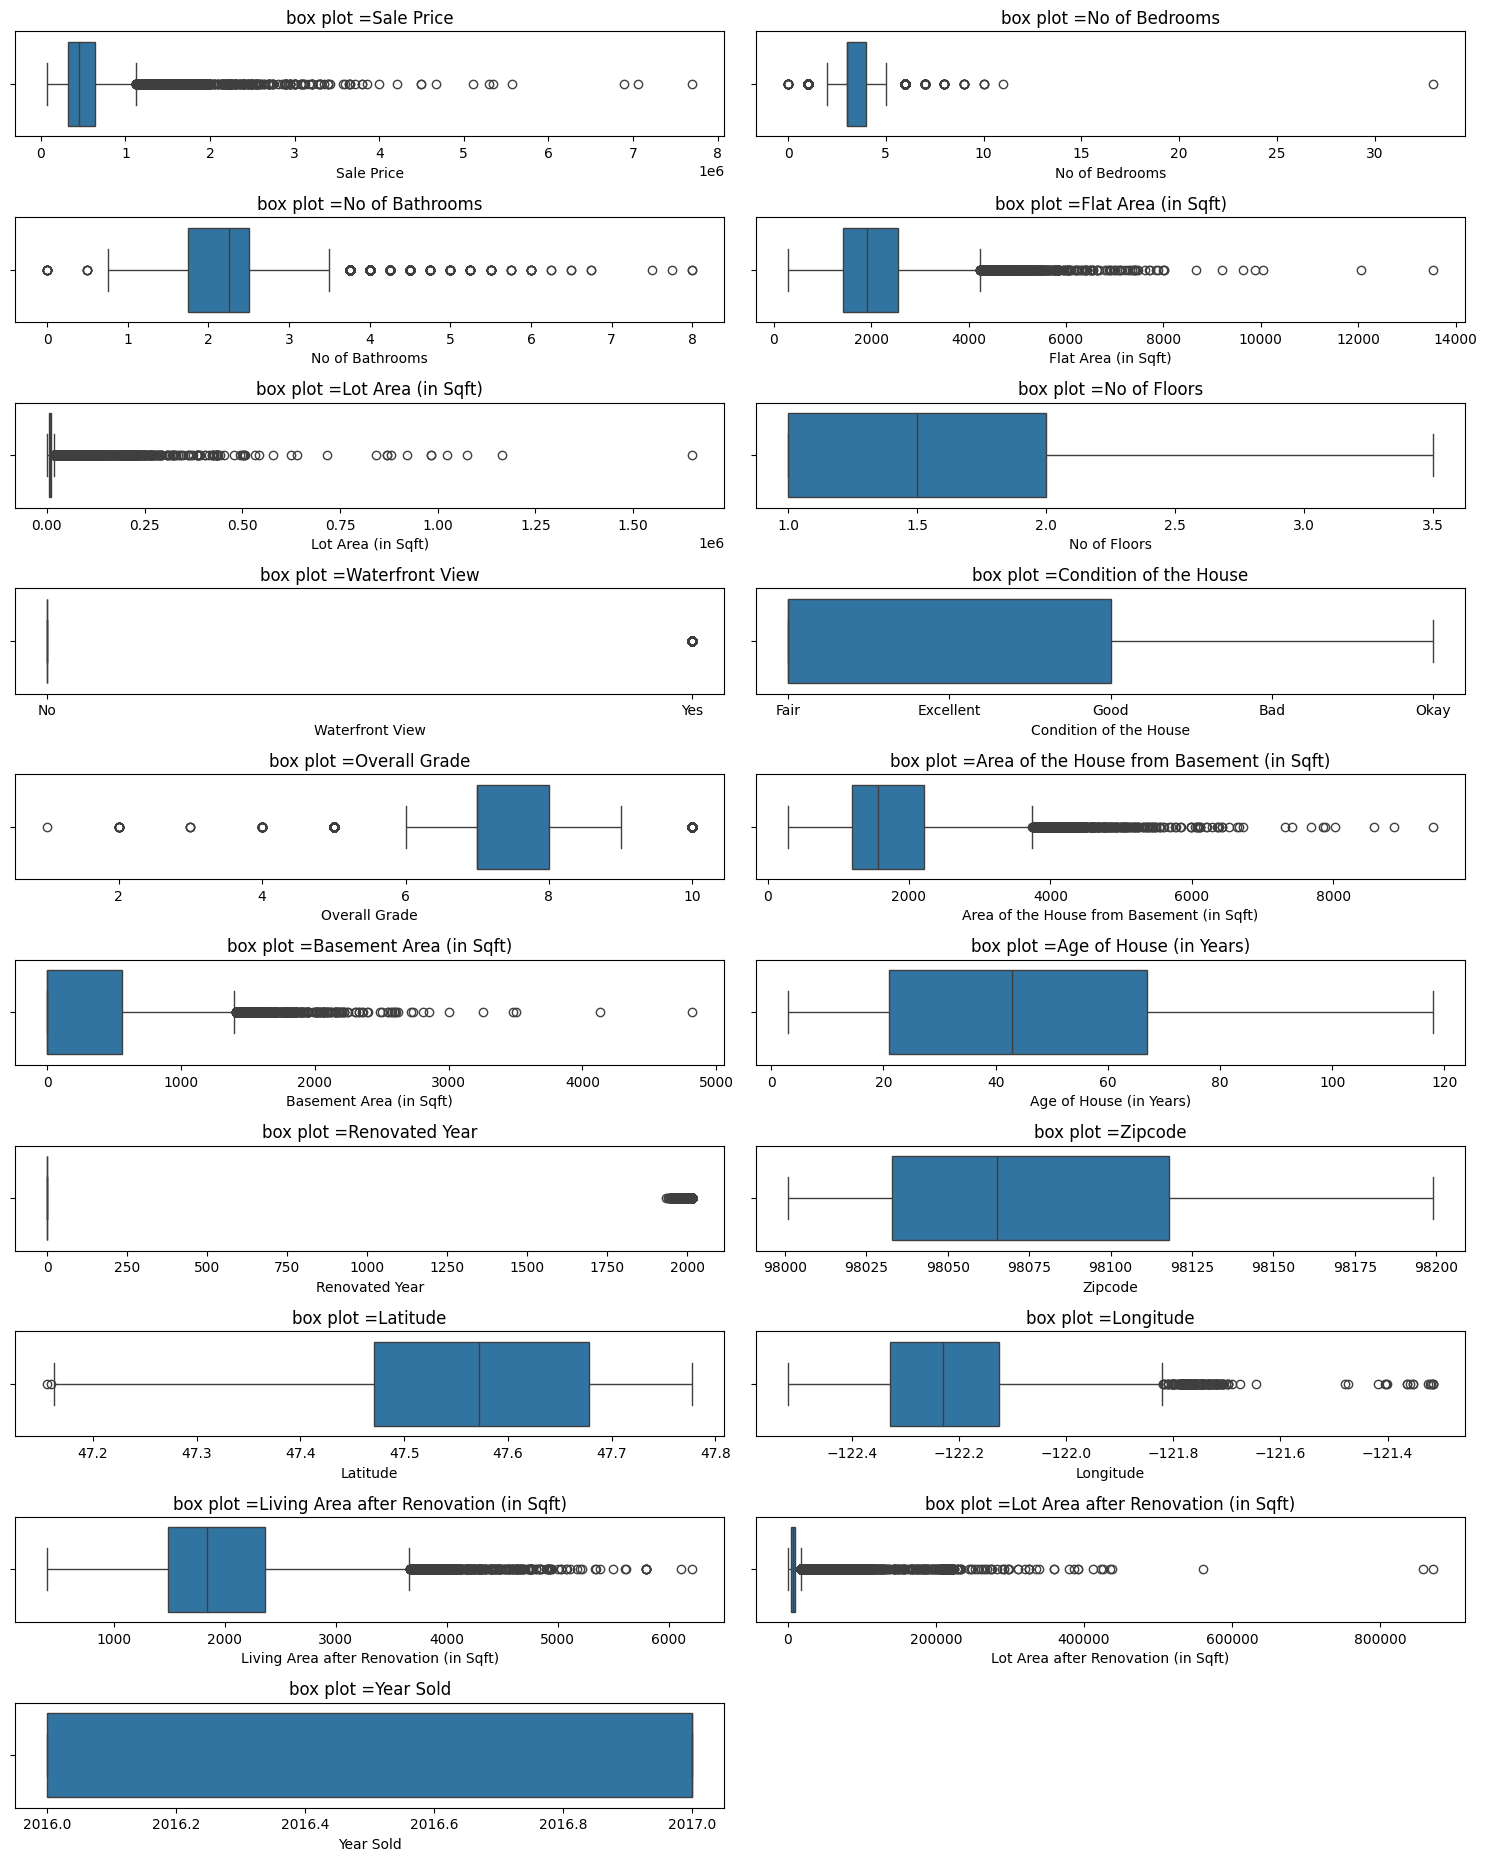

In [ ]:
columns=df.columns
plt.figure(figsize=(15,35))
for i,col in enumerate(columns):
    plt.subplot(len(columns),2,i+1)
    sns.boxplot(x=df[col])
    plt.title(f"box plot ={col}")
plt.tight_layout()
plt.show()

In [ ]:
columns = [
    'Sale Price',
    'No of Bedrooms',
    'No of Bathrooms','Flat Area (in Sqft)','Lot Area (in Sqft)','Overall Grade',
    'Area of the House from Basement (in Sqft)','Basement Area (in Sqft)','Renovated Year','Longitude',
    'Living Area after Renovation (in Sqft)','Lot Area after Renovation (in Sqft)',
]

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    # Replace outliers with upper and lower boundary limits
    df[col] = df[col].clip(lower=lower, upper=upper)


In [ ]:
df[col]=df[col].clip(upper=upper,lower=lower)# to replace the value of outiler with the

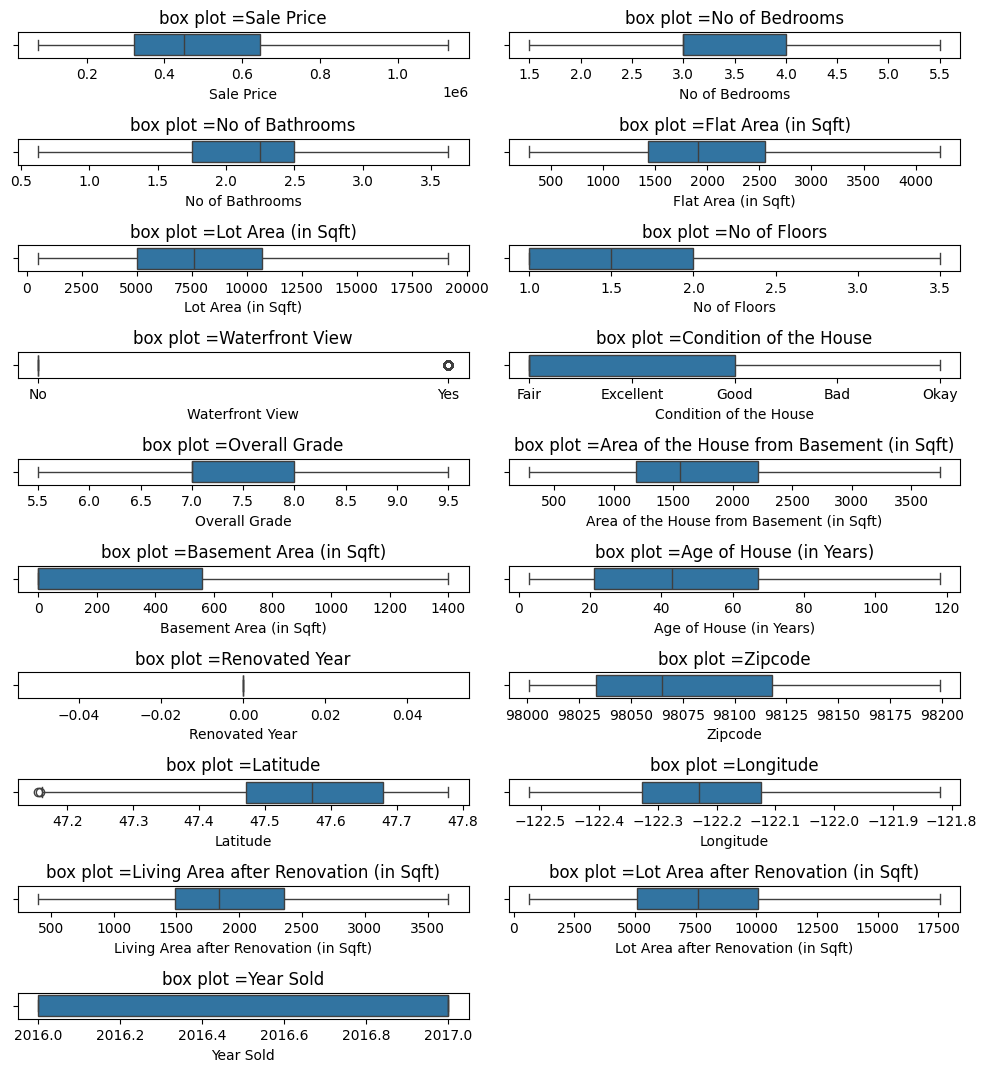

In [ ]:
columns=df.columns
plt.figure(figsize=(10,20))
for i,col in enumerate(columns):
    plt.subplot(len(columns),2,i+1)
    sns.boxplot(x=df[col])
    plt.title(f"box plot ={col}")
plt.tight_layout()
plt.show()

# f uture enchance

In [ ]:
# Selected Features

features_selected = ["Flat Area (in Sqft)","Area of the House from Basement (in Sqft)","Overall Grade"]


X_train_selected_feature = X_train_final[features_selected]
X_test_selected_feature = X_test_final[features_selected]

#  regression

In [ ]:
from sklearn.svm import SVR

## MODEL SELECTION

In [ ]:
rf= RandomForestRegressor()
lr = LinearRegression()
svm = SVR()

## Model training

In [ ]:
rf.fit(X_train_selected_feature,y_train)

svm.fit(X_train_selected_feature, y_train)
lr.fit(X_train_selected_feature,y_train)

LinearRegression()

## MODEL evaluations

### random

In [ ]:
y_predr = rf.predict(X_test_selected_feature)
y_predr

array([ 465007.6126887 ,  400812.34004196,  377685.49839466, ...,
       1438078.08      ,  273540.96671736,  678828.09301587])

In [ ]:
mean_sq_r = mean_squared_error(y_test, y_predr)
mean_ab_r = mean_absolute_error(y_test, y_predr)
r2_r = r2_score(y_test, y_predr)

print("mean sq err:", mean_sq_r)
print("mean absolute err:", mean_ab_r)
print("R2 Score:", r2_r)

mean sq err: 65333592629.79003
mean absolute err: 163114.93223838086
R2 Score: 0.551998056507148


### liner

In [ ]:
y_predl = lr.predict(X_test_selected_feature)
y_predl

array([ 670587.68620905,  347722.90589598,  398992.36409989, ...,
       1316691.28793655,  198679.13173277,  742288.85124587])

In [ ]:
mean_sq_l= mean_squared_error(y_test,y_predl)
mean_ab_l = mean_absolute_error(y_test,y_predl)
r2_l = r2_score(y_test,y_predl)
print(mean_sq_l,mean_ab_l,r2_l)

70516321218.11009 168159.989351387 0.516459333061766


### SVM

In [ ]:
y_predsvm = svm.predict(X_test_selected_feature)
y_predsvm

array([453180.42272877, 449641.70352174, 449558.79323494, ...,
       453444.20258263, 449083.26408142, 453769.65826657])

In [ ]:
mean_sq_svm= mean_squared_error(y_test,y_predsvm)
mean_ab_svm = mean_absolute_error(y_test,y_predsvm)
r2_svm = r2_score(y_test,y_predsvm)
print(mean_sq_svm,mean_ab_svm,r2_svm)

154467667341.24518 226006.2453846809 -0.05920725296424889


### result

In [ ]:
# Create a comparison DataFrame
results_df = pd.DataFrame({
    'Model': ['Random Forest', 'Linear Regression', 'SVM'],
    'MSE': [mean_squared_error(y_test, rf.predict(X_test_selected_feature)), mean_sq_l, mean_sq_svm],
    'MAE': [mean_absolute_error(y_test, rf.predict(X_test_selected_feature)), mean_ab_l, mean_ab_svm],
    'R2_Score': [r2_score(y_test, rf.predict(X_test_selected_feature)), r2_l, r2_svm]
}
)
# Find and print the best model (highest R2 Score)
best_model = results_df.loc[results_df['R2_Score'].idxmax()]
print("\n--- Best Model ---")
print(f"Model Name: {best_model['Model']}")
print(f"Highest R2 Score: {best_model['R2_Score']:.4f}")
print(f"Lowest MSE: {best_model['MSE']:.4f}")


--- Best Model ---
Model Name: Random Forest
Highest R2 Score: 0.5520
Lowest MSE: 65333592629.7900
